# Lab 02 — Data Exploration and Extraction

**Course:** MSc Data Science  
**Python:** 3.12.2

This notebook demonstrates the implementation in `src/solution.py` using the supplied `data/transactions.jsonl` file. The input file is read in its original physical order and is not modified.

Before submission, select the project **Python 3.12** kernel and use **Restart Kernel → Run All Cells**. The notebook saves generated tables and the benchmark chart in `outputs/`.


In [8]:
from pathlib import Path
import sys
import platform
import json
import time
import statistics
import tracemalloc
import copy
from decimal import Decimal
from datetime import datetime

import pandas as pd
import matplotlib.pyplot as plt

# Find the project root whether Jupyter starts in the project folder or notebooks/.
_candidates = [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _candidates if (p / "src").is_dir() and (p / "data").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Project root not found. Open this notebook inside the lab-02 project.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src import solution

data_path = ROOT / "data" / "transactions.jsonl"
outputs_dir = ROOT / "outputs"
outputs_dir.mkdir(exist_ok=True)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Project:", ROOT)
print("Input exists:", data_path.exists())
assert data_path.exists(), f"Missing input file: {data_path}"


Python: 3.14.6
Platform: Windows-11-10.0.26300-SP0
Project: C:\Users\acern\lab-02
Input exists: True


## T1 — Make and check transaction records

The event contains exactly six required fields. Text fields are stripped without changing their case, currency is stripped and converted to uppercase, the amount is represented by `Decimal`, and the timestamp must include a timezone and is converted to UTC. The amount must be finite, positive, no greater than 10^12, and exact to a cent.

**Explanation.** `Decimal` avoids binary floating-point representation errors in monetary values. The parser normalizes external input before constructing the frozen, slotted `Transaction`. A timezone-aware timestamp is converted to UTC so that records with different offsets can be compared consistently. The invalid examples below cover a Boolean amount, infinity, a fraction smaller than one cent, an unsupported currency, and a timestamp without a timezone.


In [9]:
valid_event = {
    "tx_id": " T100 ",
    "account": " A1 ",
    "category": " food ",
    "amount": "12.50",
    "occurred_at": "2026-09-01T10:00:00Z",
    "currency": " uzs "
}

transaction = solution.parse_event(valid_event)
print("Valid transaction:")
print(transaction)
assert transaction.tx_id == "T100"
assert transaction.account == "A1"
assert transaction.category == "food"
assert transaction.amount == Decimal("12.50")
assert transaction.currency == "UZS"

invalid_events = [
    {**valid_event, "amount": True},
    {**valid_event, "amount": "Infinity"},
    {**valid_event, "amount": "12.501"},
    {**valid_event, "currency": "EUR"},
    {**valid_event, "occurred_at": "2026-09-01T10:00:00"},
]

print("\nInvalid event checks:")
for event in invalid_events:
    try:
        solution.parse_event(event)
    except ValueError as exc:
        print("Rejected:", exc)
    else:
        raise AssertionError(f"Invalid event was accepted: {event}")


Valid transaction:
Transaction(tx_id='T100', account='A1', category='food', amount=Decimal('12.50'), occurred_at=datetime.datetime(2026, 9, 1, 10, 0, tzinfo=datetime.timezone.utc), currency='UZS')

Invalid event checks:
Rejected: Invalid amount type
Rejected: Invalid amount
Rejected: Invalid amount
Rejected: Currency must be UZS or USD
Rejected: Invalid datetime


## T2 — Read lines and handle repeated IDs

`iter_jsonl` is a generator: it yields one raw physical line at a time and does not load the complete file. The monitor counts every physical line, including blank lines. Its order of operations is JSON decoding, event validation, duplicate checking, anomaly checking, and state update.

**Explanation.** Duplicate detection happens only after successful validation. Therefore, a rejected record cannot reserve its transaction ID. The first valid event for an ID is accepted, and later valid events with that ID are counted as duplicates. This is important when an invalid record is followed by a corrected retry.


In [10]:
events = solution.iter_jsonl(data_path)
first_line = next(events)
print("First physical line:")
print(first_line.rstrip())
remaining_lines = sum(1 for _ in events)
events.close()
print("Remaining physical lines:", remaining_lines)

# Process the complete input once and check count reconciliation.
results = solution.monitor(solution.iter_jsonl(data_path))
metrics = results["metrics"]
print("\nMetrics:", metrics)
assert metrics["received"] == (
    metrics["accepted"] + metrics["duplicates"] + metrics["rejected"]
)
assert metrics["received"] == 20
print("Count reconciliation passed.")


First physical line:
{"tx_id": "T1", "account": "A1", "category": "food", "amount": "10.00", "occurred_at": "2026-09-01T10:00:00Z", "currency": "UZS"}
Remaining physical lines: 19

Metrics: {'received': 20, 'accepted': 11, 'duplicates': 1, 'rejected': 8}
Count reconciliation passed.


## T3 — Keep recent amounts and find anomalies

Each account has its own bounded rolling window. The running total is updated in constant time: when the window is full, the oldest amount is subtracted before the new amount is added. Anomaly detection uses the **prior** window and runs before the current payment is inserted.

**Explanation.** At least three earlier accepted payments are required. With prior values `[10, 11, 12]`, the mean is 11, so an amount of 22 is exactly at the threshold (`2 × 11`) and is flagged. A flagged payment is still accepted and updates the account totals and rolling window. Invalid records and duplicates do not update the window.


In [11]:
# Exact-threshold example.
window = solution.RollingWindow(size=3)
for amount in ("10.00", "11.00", "12.00"):
    window.push(Decimal(amount))
prior_mean = window.mean
new_amount = Decimal("22.00")
print("Prior values:", window.values)
print("Prior mean:", prior_mean)
print("New amount:", new_amount)
print("Threshold:", Decimal("2") * prior_mean)
assert new_amount >= Decimal("2") * prior_mean
window.push(new_amount)
print("Window after accepted payment:", window.values)

# Full dataset results.
results = solution.monitor(solution.iter_jsonl(data_path))
print("\nMetrics:")
print(results["metrics"])
print("\nAccount summary:")
display(results["summary"])
print("Anomalies:")
display(results["anomalies"])
print("Rejected lines:")
display(results["rejected"])

assert results["metrics"] == {
    "received": 20, "accepted": 11, "duplicates": 1, "rejected": 8
}
assert len(results["anomalies"]) == 3
assert len(results["rejected"]) == 8
print("All T3 checks passed.")


Prior values: (Decimal('10.00'), Decimal('11.00'), Decimal('12.00'))
Prior mean: 11.00
New amount: 22.00
Threshold: 22.00
Window after accepted payment: (Decimal('11.00'), Decimal('12.00'), Decimal('22.00'))

Metrics:
{'received': 20, 'accepted': 11, 'duplicates': 1, 'rejected': 8}

Account summary:


,account,count,total,mean,dominant_category,window_values,window_mean
0,A1,6,168.00,28.00,food,"(22.00, 13.00, 100.00)",45.00
1,A2,5,1.10,0.22,travel,"(0.30, 0.40, 0.10)",0.2666666666666666666666666667


Anomalies:


,line,tx_id,account,amount,prior_mean,ratio
0,5,T4,A1,22.00,11.00,2
1,11,B4,A2,0.40,0.20,2
2,19,T6,A1,100.00,15.66666666666666666666666667,6.382978723404255319148936169


Rejected lines:


,line,reason
0,7,invalid_event
1,12,invalid_event
2,13,invalid_event
3,14,invalid_event
4,15,invalid_event
5,16,invalid_event
6,17,invalid_event
7,18,invalid_json


All T3 checks passed.


## T4 — Measure time and memory

The benchmark compares membership queries in a list and a set for three collection sizes. It performs five repeats and reports the median time for 500 queries. The collection is constructed **outside** the timed section, so the measurement covers membership queries only. The absent target makes list lookup scan the collection.

The memory experiment compares counting lines from the lazy iterator with first loading all lines into a list. `tracemalloc` measures Python memory allocations; it does not measure every native allocation or total operating-system process memory. The small supplied input may produce only a small difference, so the result should be interpreted as an illustration rather than a universal memory ratio.


List vs set membership (median milliseconds for 500 queries):


,size,repeats,queries_per_repeat,list_median_ms,set_median_ms,list_us_per_query,set_us_per_query
0,100,5,500,1.4373,0.1069,2.8746,0.2138
1,1000,5,500,11.4398,0.0865,22.8796,0.1730
2,10000,5,500,113.3208,0.0834,226.6416,0.1668



Lazy vs eager input memory:


,method,lines,peak_memory_bytes,peak_memory_kb
0,Lazy,20,141293,137.981445
1,Eager,20,144336,140.953125


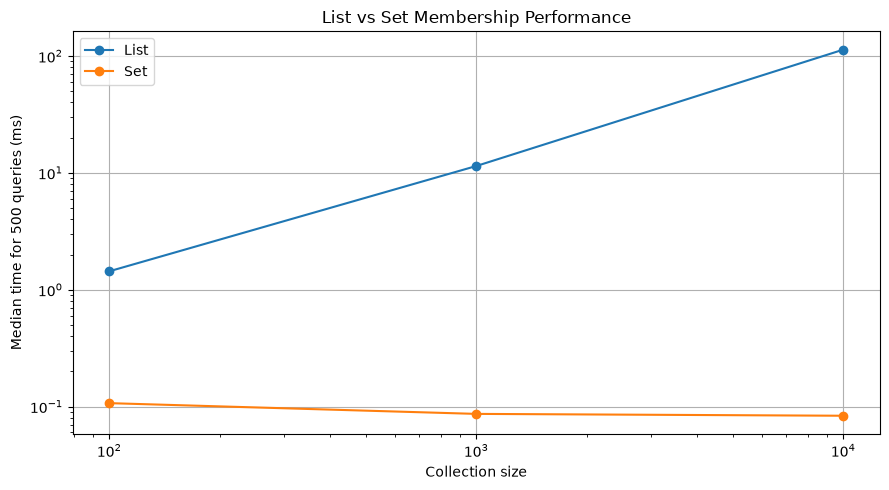

Python version: 3.14.6
Platform: Windows-11-10.0.26300-SP0
Repeats: 5 | Queries per repeat: 500
Timing excludes collection construction.
Memory values are tracemalloc peak Python allocations.


In [12]:
sizes = [100, 1_000, 10_000]
repeats = 5
queries = 500
target = -1  # Absent target: full list scan.
benchmark_rows = []

for size in sizes:
    values_list = list(range(size))
    values_set = set(values_list)
    list_times = []
    set_times = []

    for _ in range(repeats):
        start = time.perf_counter()
        for _ in range(queries):
            target in values_list
        list_times.append(time.perf_counter() - start)

        start = time.perf_counter()
        for _ in range(queries):
            target in values_set
        set_times.append(time.perf_counter() - start)

    list_median_ms = statistics.median(list_times) * 1_000
    set_median_ms = statistics.median(set_times) * 1_000
    benchmark_rows.append({
        "size": size,
        "repeats": repeats,
        "queries_per_repeat": queries,
        "list_median_ms": list_median_ms,
        "set_median_ms": set_median_ms,
        "list_us_per_query": list_median_ms * 1_000 / queries,
        "set_us_per_query": set_median_ms * 1_000 / queries,
    })

benchmark_df = pd.DataFrame(benchmark_rows)
print("List vs set membership (median milliseconds for 500 queries):")
display(benchmark_df)
benchmark_df.to_csv(outputs_dir / "t4_benchmark.csv", index=False)

# Measure peak traced allocations for lazy and eager reading.
def peak_memory(callable_):
    tracemalloc.start()
    try:
        result = callable_()
        _current, peak = tracemalloc.get_traced_memory()
    finally:
        tracemalloc.stop()
    return peak, result

lazy_peak, lazy_count = peak_memory(
    lambda: sum(1 for _ in solution.iter_jsonl(data_path))
)
eager_peak, eager_lines = peak_memory(
    lambda: list(solution.iter_jsonl(data_path))
)
memory_df = pd.DataFrame([
    {"method": "Lazy", "lines": lazy_count, "peak_memory_bytes": lazy_peak, "peak_memory_kb": lazy_peak / 1024},
    {"method": "Eager", "lines": len(eager_lines), "peak_memory_bytes": eager_peak, "peak_memory_kb": eager_peak / 1024},
])
print("\nLazy vs eager input memory:")
display(memory_df)
memory_df.to_csv(outputs_dir / "t4_memory.csv", index=False)

plt.figure(figsize=(9, 5))
plt.plot(benchmark_df["size"], benchmark_df["list_median_ms"], marker="o", label="List")
plt.plot(benchmark_df["size"], benchmark_df["set_median_ms"], marker="o", label="Set")
plt.xlabel("Collection size")
plt.ylabel(f"Median time for {queries} queries (ms)")
plt.title("List vs Set Membership Performance")
plt.xscale("log")
plt.yscale("log")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(outputs_dir / "t4_benchmark.png", dpi=150, bbox_inches="tight")
plt.show()

print("Python version:", sys.version.split()[0])
print("Platform:", platform.platform())
print("Repeats:", repeats, "| Queries per repeat:", queries)
print("Timing excludes collection construction.")
print("Memory values are tracemalloc peak Python allocations.")


## T5 — Explain choices and limits

A reference, shallow copy, and deep copy behave differently for nested data. A reference is another name for the same object. A shallow copy creates a new outer dictionary but keeps references to nested objects. A deep copy recursively creates independent nested objects.

The first three accepted payments cannot be flagged because the rule needs three prior amounts. A flagged large payment is still accepted and can increase the next window mean. The program uses physical arrival order, not event-time order; an event with an older timestamp is compared with the state already processed. Event-time processing could reorder or buffer records, but would need a policy for late events. A rolling median is an alternative baseline and is less affected by one extreme value, although it may react more slowly to real changes.

Let U be unique valid IDs, A the number of accounts, W the window size, C the number of stored account-category combinations, and O the retained output rows. Approximate memory use is **O(U + A × W + C + O)**. The windows are bounded, but the ID set and output tables can grow. Expiring old IDs after a retention period reduces memory, but a repeated ID arriving after expiry could be accepted again; duplicate detection would then be guaranteed only within the retention period.


In [13]:
original = {
    "tx_id": "T100",
    "amount": 100,
    "details": {"category": "food", "tags": ["online", "card"]},
}
reference = original
shallow = copy.copy(original)
deep = copy.deepcopy(original)

reference["details"]["tags"].append("reference_change")
print("Reference changes original nested data:", original["details"]["tags"])
original["details"]["tags"].remove("reference_change")

shallow["details"]["tags"].append("shallow_change")
print("Shallow copy shares nested data:", original["details"]["tags"])
original["details"]["tags"].remove("shallow_change")

deep["details"]["tags"].append("deep_change")
print("Original after deep-copy change:", original["details"]["tags"])
print("Deep copy nested data:", deep["details"]["tags"])

assert reference is original
assert shallow is not original and shallow["details"] is original["details"]
assert deep is not original and deep["details"] is not original["details"]
print("Copy checks passed.")


Reference changes original nested data: ['online', 'card', 'reference_change']
Shallow copy shares nested data: ['online', 'card', 'shallow_change']
Original after deep-copy change: ['online', 'card']
Deep copy nested data: ['online', 'card', 'deep_change']
Copy checks passed.


## T6 — Export results and final checks

The final cell saves the four required monitor outputs in both CSV and JSON formats. Decimal values are serialized as strings to preserve their exact decimal representation. The benchmark table, memory table, and labeled chart are also stored in `outputs/`.

**Final interpretation.** The supplied file contains 20 physical lines. The monitor accepts 11 valid unique transactions, counts one valid duplicate, and rejects eight invalid records. The reconciliation equation is therefore 20 = 11 + 1 + 8. Three accepted payments meet the anomaly threshold. An anomaly is a warning produced by the defined comparison rule; it is not proof of fraud. The summary and anomaly tables retain the order and aggregation rules required by the function guide.

Before submitting, run this notebook from a fresh Python 3.12 kernel and run the public tests from the project root with `python -m unittest discover -s tests -p "test_public.py" -v`. Keep `REPORT.md` and `AI_USE.md` as separate project files, and do not commit `.venv` or credentials.


In [14]:
# Re-run monitor for the final export.
final_result = solution.monitor(solution.iter_jsonl(data_path))

def json_serializer(value):
    if isinstance(value, Decimal):
        return str(value)
    if isinstance(value, datetime):
        return value.isoformat()
    raise TypeError(f"Cannot serialize {type(value).__name__}")

with open(outputs_dir / "metrics.json", "w", encoding="utf-8") as file:
    json.dump(final_result["metrics"], file, indent=2)
with open(outputs_dir / "summary.json", "w", encoding="utf-8") as file:
    json.dump(final_result["summary"].to_dict(orient="records"), file, indent=2, default=json_serializer)
with open(outputs_dir / "anomalies.json", "w", encoding="utf-8") as file:
    json.dump(final_result["anomalies"].to_dict(orient="records"), file, indent=2, default=json_serializer)
with open(outputs_dir / "rejected.json", "w", encoding="utf-8") as file:
    json.dump(final_result["rejected"].to_dict(orient="records"), file, indent=2, default=json_serializer)

final_result["summary"].to_csv(outputs_dir / "summary.csv", index=False)
final_result["anomalies"].to_csv(outputs_dir / "anomalies.csv", index=False)
final_result["rejected"].to_csv(outputs_dir / "rejected.csv", index=False)

assert final_result["metrics"] == {"received": 20, "accepted": 11, "duplicates": 1, "rejected": 8}
required_outputs = [
    "metrics.json", "summary.json", "summary.csv",
    "anomalies.json", "anomalies.csv",
    "rejected.json", "rejected.csv",
    "t4_benchmark.csv", "t4_memory.csv", "t4_benchmark.png",
]
missing = [name for name in required_outputs if not (outputs_dir / name).exists()]
assert not missing, f"Missing output files: {missing}"
print("Final metrics:", final_result["metrics"])
print("All output files created:")
for name in required_outputs:
    print("-", name)
print("\nNotebook checks completed.")


Final metrics: {'received': 20, 'accepted': 11, 'duplicates': 1, 'rejected': 8}
All output files created:
- metrics.json
- summary.json
- summary.csv
- anomalies.json
- anomalies.csv
- rejected.json
- rejected.csv
- t4_benchmark.csv
- t4_memory.csv
- t4_benchmark.png

Notebook checks completed.
